# 19. KEGG cross-ontology check

KEGG provides pathway maps that connect genes involved in related biological activities. The audit counted training support within these pathways and compared high- and low-support predictions in held-out cell types under both few-shot and zero-shot evaluation.

**Original agent determination:** High-minus-low overlap@N: few-shot HVG +0.141, SE +0.128. Zero-shot HVG +0.066, SE +0.047.

This notebook reconstructs the June primary run from its original downloads, split files, processing code and saved agent decisions. STATE was evaluated through the official scored-output repositories in that run.

**Portable input setup.** Install `../requirements.txt` in a Python3.11 environment. The first code cell restores the exact offline payloads included in this checkout, verifies their hashes, and then runs the original scored-output analysis. No model inference is performed. Historical saved curves remain visible; a clean run rebuilds its own `computed/` tables. See `../README.md`.

In [1]:
from pathlib import Path
import sys, json
root=next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'recovered_pipeline.py').is_file())
sys.path.insert(0,str(root))
import pandas as pd
from IPython.display import display, Markdown
from state_inputs import ensure_inputs
print(ensure_inputs())
import recovered_pipeline as rp
import notebook_support as ns


{'profile': 'default', 'verified_files': 226, 'assets': [{'asset': 'state-historical-comparison-tables.tar.gz', 'members': 25, 'source': 'verified_existing_inputs'}, {'asset': 'state-official-score-cache.tar.gz', 'members': 193, 'source': 'verified_existing_inputs'}, {'asset': 'state-historical-annotations.tar.gz', 'members': 8, 'source': 'verified_existing_inputs'}], 'new_model_inference': False}


Matplotlib is building the font cache; this may take a moment.


## Original acquisition and inputs

The original downloader and processing scripts are preserved unchanged under `original/`. The replay resolves their downloads to the recovered cache at the recorded repository revisions, so no current dataset replaces the original bytes. Original downloads, processing and plotting are separate visible steps below.

In [2]:
verification=rp.run_stage('ontology')
ns.show_acquisition('ontology')


,repo,revision
0,arcinstitute/ST-HVG-Tahoe,ca6b751972493f8448e3256d1340ae70ad43e1e7
1,arcinstitute/ST-SE-Tahoe,03b1971d7cc93a7535fd2e957c6948dba267378b
2,arcinstitute/ST-HVG-Replogle,bb6a9562cbbf1fd152df14cc53b4cc7517c77175
3,arcinstitute/ST-SE-Replogle,e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c
4,arcinstitute/ST-HVG-Parse,827df657cd87063026d2abefd73e99036755ac1b
5,arcinstitute/ST-SE-Parse,fa458ffda8690c5c5bdff080dfdc46b46713043b
6,tahoebio/Tahoe-100M,2dc57900b7981cfcf5e211527169a0b006546a95


Original evaluation used official scored CSVs. The replay loads the original cached bytes at these revisions.
All 55 score filenames and the three metadata downloads are in computed/initial/artifacts/download_revisions.json.
Initial acquisition implementation: original/state_generalizability_20260602_single_controller/scripts/run_state_spectra_audit.py
Annotation snapshots and split inputs: original/state_generalizability_continued_20260603/external and original/state_generalizability_20260602_single_controller/external/state/state_preprint_toml_files.


,source,original_download_URL
0,GOA,https://current.geneontology.org/annotations/g...
1,GO_basic,https://current.geneontology.org/ontology/go-b...
2,WikiPathways,https://data.wikipathways.org/current/gmt/wiki...
3,KEGG_list_hsa,https://rest.kegg.jp/list/hsa
4,KEGG_list_pathway,https://rest.kegg.jp/list/pathway/hsa
5,KEGG_link_pathway,https://rest.kegg.jp/link/pathway/hsa


## Original processing code

These are the original functions used for this analysis. `recovered_pipeline.py` changes their filesystem destinations and uses the original cached downloads; it writes regenerated products only to `computed/`. Set `force=True` in `run_stage` to recompute this stage after its prerequisites.

In [3]:
ns.show_code('ontology',19)

/opt/homebrew/anaconda3/envs/fleming/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


```python
def parse_kegg(alias: dict[str, str]) -> dict[str, set[str]]:
    list_path = EXT / "kegg_list_hsa.txt"
    pathway_path = EXT / "kegg_list_pathway_hsa.txt"
    link_path = EXT / "kegg_link_pathway_hsa.txt"
    ok = (
        fetch_text(KEGG_LIST_HSA, list_path)
        and fetch_text(KEGG_LIST_PATHWAY, pathway_path)
        and fetch_text(KEGG_LINK_PATHWAY, link_path)
    )
    if not ok:
        return {}
    gene_to_symbol: dict[str, set[str]] = defaultdict(set)
    with list_path.open(errors="replace") as handle:
        for line in handle:
            if "\t" not in line:
                continue
            kid, desc = line.rstrip("\n").split("\t", 1)
            symbols = desc.split(";", 1)[0]
            for sym in re.split(r",\s*", symbols):
                cs = canonical(sym, alias)
                if cs:
                    gene_to_symbol[kid].add(cs)
    pathway_names: dict[str, str] = {}
    with pathway_path.open(errors="replace") as handle:
        for line in handle:
            if "\t" not in line:
                continue
            pid, name = line.rstrip("\n").split("\t", 1)
            pathway_names[f"path:{pid}"] = name
    out: dict[str, set[str]] = defaultdict(set)
    with link_path.open(errors="replace") as handle:
        for line in handle:
            if "\t" not in line:
                continue
            kid, pid = line.rstrip("\n").split("\t", 1)
            pname = pathway_names.get(pid, pid)
            for sym in gene_to_symbol.get(kid, set()):
                out[sym].add(pname)
    return dict(out)

```

```python
def build_fewshot_examples(df: pd.DataFrame, alias: dict[str, str], feature_map: dict[str, set[str]], collection: str) -> pd.DataFrame:
    sub = df[(df["dataset_family"] == "Replogle-Nadig") & (df["protocol"] == "fewshot")].copy()
    sub["gene_symbol_canonical"] = sub["gene_symbol"].map(lambda x: canonical(x, alias))
    sub = sub[sub["gene_symbol_canonical"] != "NON-TARGETING"].copy()
    train_by_context = infer_fewshot_train_sets(df, alias)
    rows = []
    for ctx, ctx_df in sub.groupby("context"):
        train = train_by_context.get(str(ctx), set())
        idx = feature_index(feature_map, train)
        for row_index, row in ctx_df.iterrows():
            gene = row["gene_symbol_canonical"]
            feats = feature_map.get(gene, set())
            raw, norm, frac, n_features = support_stat(feats, idx, len(train))
            rows.append(
                {
                    "row_index": row_index,
                    "collection": collection,
                    "train_gene_count": len(train),
                    "feature_count": n_features,
                    "support_log_mean": raw,
                    "support_norm_log_mean": norm,
                    "supported_fraction": frac,
                }
            )
    feat = pd.DataFrame(rows).set_index("row_index")
    out = sub.join(feat)
    out["spectra_subset"] = np.where(out["context"].isin({"hepg2", "k562"}), "discovery_hepg2_k562", "confirmation_jurkat_rpe1")
    return out

```

```python
def build_zeroshot_examples(df: pd.DataFrame, alias: dict[str, str], feature_map: dict[str, set[str]], collection: str) -> pd.DataFrame:
    sub = df[(df["dataset_family"] == "Replogle-Nadig") & (df["protocol"] == "zeroshot")].copy()
    sub["gene_symbol_canonical"] = sub["gene_symbol"].map(lambda x: canonical(x, alias))
    sub = sub[sub["gene_symbol_canonical"] != "NON-TARGETING"].copy()
    all_by_context = {
        str(ctx): {canonical(g, alias) for g in ctx_df["gene_symbol"].dropna() if canonical(g, alias) != "NON-TARGETING"}
        for ctx, ctx_df in sub.groupby("context")
    }
    contexts = set(all_by_context)
    rows = []
    for ctx, ctx_df in sub.groupby("context"):
        train = set().union(*(all_by_context[c] for c in contexts - {str(ctx)}))
        idx = feature_index(feature_map, train)
        for row_index, row in ctx_df.iterrows():
            gene = row["gene_symbol_canonical"]
            feats = feature_map.get(gene, set())
            raw, norm, frac, n_features = support_stat(feats, idx, len(train))
            rows.append(
                {
                    "row_index": row_index,
                    "collection": collection,
                    "zeroshot_train_gene_count": len(train),
                    "feature_count": n_features,
                    "support_log_mean": raw,
                    "support_norm_log_mean": norm,
                    "supported_fraction": frac,
                }
            )
    feat = pd.DataFrame(rows).set_index("row_index")
    out = sub.join(feat)
    out["spectra_subset"] = "zeroshot_cross_protocol_confirmation"
    return out

```

```python
def test_collection(df: pd.DataFrame, alias: dict[str, str], name: str, feature_map: dict[str, set[str]]) -> dict[str, object]:
    if not feature_map:
        return {"collection": name, "status": "not_available"}
    few = build_fewshot_examples(df, alias, feature_map, name)
    discovery = few[(few["spectra_subset"] == "discovery_hepg2_k562") & (few["feature_count"] > 0)]
    positive = discovery["support_norm_log_mean"].dropna()
    positive = positive[positive > 0]
    if positive.nunique() < 4:
        return {"collection": name, "status": "not_evaluable", "reason": "insufficient nonzero support diversity"}
    cutpoints = [float(x) for x in positive.quantile([0.25, 0.50, 0.75]).tolist()]
    few["support_level"] = assign_bins(few["support_norm_log_mean"], few["feature_count"], cutpoints)
    zero = build_zeroshot_examples(df, alias, feature_map, name)
    zero["support_level"] = assign_bins(zero["support_norm_log_mean"], zero["feature_count"], cutpoints)

    safe = re.sub(r"[^a-z0-9]+", "_", name.lower()).strip("_")
    few.to_csv(READY / f"multi_pathway_{safe}_fewshot_examples.csv", index=False)
    zero.to_csv(READY / f"multi_pathway_{safe}_zeroshot_examples.csv", index=False)
    few_levels, few_trends = summarize(few, "support_level")
    zero_levels, zero_trends = summarize(zero, "support_level")
    levels = pd.concat([few_levels, zero_levels], ignore_index=True)
    trends = pd.concat([few_trends, zero_trends], ignore_index=True)
    levels.to_csv(ART / f"spc_multi_pathway_{safe}.csv", index=False)
    trends.to_csv(ART / f"spc_multi_pathway_{safe}_trends.csv", index=False)

    conf = trends[trends["spectra_subset"] == "confirmation_jurkat_rpe1"]
    zconf = trends[trends["spectra_subset"] == "zeroshot_cross_protocol_confirmation"]
    decision = (
        len(conf) == 2
        and len(zconf) == 2
        and conf["similarity_monotone_increasing"].all()
        and zconf["similarity_monotone_increasing"].all()
        and (conf["n_levels"] >= 3).all()
        and (zconf["n_levels"] >= 3).all()
        and (conf["high_minus_low_overlap_at_N"] > 0).all()
        and (zconf["high_minus_low_overlap_at_N"] > 0).all()
    )
    ols = ols_support_coef(few)
    result = {
        "collection": name,
        "status": "supports_broader_claim" if decision else "does_not_support_broader_claim",
        "n_genes_with_features": int(sum(1 for feats in feature_map.values() if feats)),
        "n_unique_features": int(len(set().union(*feature_map.values()))) if feature_map else 0,
        "cutpoints_from_fewshot_discovery_norm_support": cutpoints,
        "fewshot_confirmation_hvg_gap": float(conf[conf["representation"] == "HVG"]["high_minus_low_overlap_at_N"].iloc[0]) if not conf[conf["representation"] == "HVG"].empty else float("nan"),
        "fewshot_confirmation_se_gap": float(conf[conf["representation"] == "SE"]["high_minus_low_overlap_at_N"].iloc[0]) if not conf[conf["representation"] == "SE"].empty else float("nan"),
        "zeroshot_hvg_gap": float(zconf[zconf["representation"] == "HVG"]["high_minus_low_overlap_at_N"].iloc[0]) if not zconf[zconf["representation"] == "HVG"].empty else float("nan"),
        "zeroshot_se_gap": float(zconf[zconf["representation"] == "SE"]["high_minus_low_overlap_at_N"].iloc[0]) if not zconf[zconf["representation"] == "SE"].empty else float("nan"),
        "fewshot_support_coef_controlled": ols,
        "levels_artifact": str(ART / f"spc_multi_pathway_{safe}.csv"),
        "trends_artifact": str(ART / f"spc_multi_pathway_{safe}_trends.csv"),
    }
    return result

```

## Recomputed sample membership, values and result

In [4]:
display(verification)

{'comparisons': {'reactome_fewshot': {'rows': 8116,
   'differences': {'feature_count': 0,
    'support_norm_log_mean': 0,
    'support_level': 0},
   'all_match': True},
  'reactome_zeroshot': {'rows': 11518,
   'differences': {'feature_count': 0,
    'support_norm_log_mean': 0,
    'support_level': 0},
   'all_match': True},
  'hgnc_gene_group_fewshot': {'rows': 8116,
   'differences': {'feature_count': 0,
    'support_norm_log_mean': 0,
    'support_level': 0},
   'all_match': True},
  'hgnc_gene_group_zeroshot': {'rows': 11518,
   'differences': {'feature_count': 0,
    'support_norm_log_mean': 0,
    'support_level': 0},
   'all_match': True},
  'go_bp_fewshot': {'rows': 8116,
   'differences': {'feature_count': 0,
    'support_norm_log_mean': 0,
    'support_level': 0},
   'all_match': True},
  'go_bp_zeroshot': {'rows': 11518,
   'differences': {'feature_count': 0,
    'support_norm_log_mean': 0,
    'support_level': 0},
   'all_match': True},
  'go_mf_fewshot': {'rows': 8116,
 

{'rows': 30,
 'differences': {'n_rows': 0,
  'similarity_mean': 0,
  'overlap_at_N_mean': 0,
  'de_sig_genes_recall_mean': 0,
  'pearson_delta_mean': 0},
 'all_match': True}

,spectra_subset,representation,level,level_order,n_rows,n_unique_contexts,n_unique_perturbations,similarity_mean,feature_count_mean,overlap_at_N_mean,de_sig_genes_recall_mean,pearson_delta_mean
0,confirmation_jurkat_rpe1,HVG,L0_no_annotation,0,990,2,690,0.000000,0.000000,0.198381,0.229428,0.394450
1,confirmation_jurkat_rpe1,HVG,L1_low,1,366,2,281,0.199657,6.237705,0.214617,0.251473,0.395958
2,confirmation_jurkat_rpe1,HVG,L2_mid,2,267,2,232,0.314048,3.692884,0.255451,0.292090,0.473184
3,confirmation_jurkat_rpe1,HVG,L3_high,3,223,2,196,0.381990,3.071749,0.244157,0.276728,0.480929
4,confirmation_jurkat_rpe1,HVG,L4_very_high,4,299,2,234,0.515458,3.026756,0.339836,0.373150,0.543474
5,confirmation_jurkat_rpe1,SE,L0_no_annotation,0,990,2,690,0.000000,0.000000,0.152148,0.181906,0.337789
6,confirmation_jurkat_rpe1,SE,L1_low,1,366,2,281,0.199657,6.237705,0.165896,0.198895,0.339665
7,confirmation_jurkat_rpe1,SE,L2_mid,2,267,2,232,0.314048,3.692884,0.208565,0.250398,0.412228
8,confirmation_jurkat_rpe1,SE,L3_high,3,223,2,196,0.381990,3.071749,0.197308,0.235043,0.443092
9,confirmation_jurkat_rpe1,SE,L4_very_high,4,299,2,234,0.515458,3.026756,0.279989,0.329213,0.502654


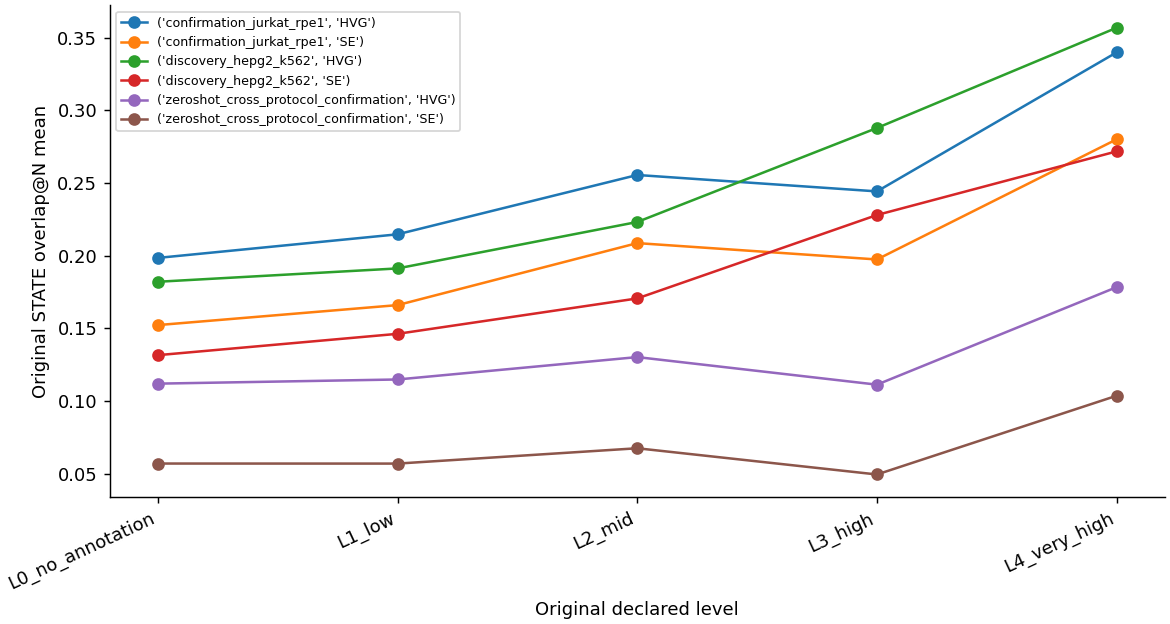

Curves are recalculated means under the original grouping rule. No new confidence bands have been added.


In [5]:
curve=ns.compare_curve('spc_multi_pathway_kegg.csv', initial=False)
ns.show_curve(curve)

## Original agent decision and supporting diagnostics

The following records preserve the agent’s actual determination, including rejected candidates and controls. Their historical status labels are shown as recorded.

In [6]:
screen=pd.read_csv(rp.CONTINUED/'artifacts/multi_pathway_support_screen.csv')
display(screen[screen.collection=='KEGG'])
display(pd.read_csv(rp.COMPUTED/'continued/artifacts/spc_multi_pathway_kegg_trends.csv'))

,collection,status,n_genes_with_features,n_unique_features,cutpoints_from_fewshot_discovery_norm_support,fewshot_confirmation_hvg_gap,fewshot_confirmation_se_gap,zeroshot_hvg_gap,zeroshot_se_gap,fewshot_support_coef_controlled,levels_artifact,trends_artifact
6,KEGG,supports_broader_claim,29104,371,"[0.2690731414998516, 0.34765048335345344, 0.42...",0.141454,0.127841,0.066405,0.046664,"{'n_rows': 4414, 'coef': 0.025459552357949278,...",/ewsc/yektefai/spectra_runs/state_generalizabi...,/ewsc/yektefai/spectra_runs/state_generalizabi...


,spectra_subset,representation,n_levels,n_rows,similarity_monotone_increasing,spearman_level_vs_overlap_at_N,low_level,high_level,low_overlap_at_N_mean,high_overlap_at_N_mean,high_minus_low_overlap_at_N
0,confirmation_jurkat_rpe1,HVG,5,2145,True,0.9,L0_no_annotation,L4_very_high,0.198381,0.339836,0.141454
1,confirmation_jurkat_rpe1,SE,5,2145,True,0.9,L0_no_annotation,L4_very_high,0.152148,0.279989,0.127841
2,discovery_hepg2_k562,HVG,5,1913,True,1.0,L0_no_annotation,L4_very_high,0.181959,0.356771,0.174812
3,discovery_hepg2_k562,SE,5,1913,True,1.0,L0_no_annotation,L4_very_high,0.131452,0.271697,0.140245
4,zeroshot_cross_protocol_confirmation,HVG,5,5759,True,0.4,L0_no_annotation,L4_very_high,0.111848,0.178253,0.066405
5,zeroshot_cross_protocol_confirmation,SE,5,5759,True,0.3,L0_no_annotation,L4_very_high,0.056862,0.103526,0.046664


All source files, downloaded inputs and historical outputs are checksummed in `original_manifest.json`. The full preliminary candidate screening and download inventory are retained in notebook `00-original-downloads-and-axis-history.ipynb`.